# Fusing the Exponential into the Multiply: an Open-Source Reproduction of ExpMul for FlashAttention-2

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Guo-4869/FlashAttention_Silicon/blob/main/flash_attn_expmul.ipynb) (repository notebook) ·
[![GitHub](https://img.shields.io/badge/GitHub-FlashAttention__Silicon-181717?logo=github)](https://github.com/Guo-4869/FlashAttention_Silicon)

**Paper reproduced:** [arXiv:2505.14314](https://arxiv.org/abs/2505.14314) ·
**Reference implementation:** [ic-lab-duth/Fused-ExpMul](https://github.com/ic-lab-duth/Fused-ExpMul) (MIT) ·
**This notebook:** [GitHub](https://github.com/Guo-4869/FlashAttention_Silicon/blob/main/flash_attn_expmul.ipynb)

Submission to the IEEE SSCS Open-Source Ecosystem "Code-a-Chip" Travel Grant Awards at ISSCC'27

| Name | Affiliation | IEEE Member | SSCS Member | Email |
|---|---|---|---|---|
| Zhipeng Guo (Leader) | University of Chinese Academy of Sciences | No | No | guozhipeng25@mails.ucas.ac.cn |



`SPDX-License-Identifier: MIT` · Tools: MSVC / g++, Python 3.12 + NumPy + gdstk, Icarus Verilog 12,
Yosys 0.68 + ABC, OpenROAD (OpenROAD-flow-scripts), nangate45 open-cell library (45 nm).

## Abstract

FlashAttention-2 computes attention online and keeps only a running maximum, a running sum of
exponentials and a running output. The paper under reproduction observes that the scalar
exponential and the two vector multiplications of the update can be fused into one operator,
`ExpMul(x, V) = e^x·V`, which replaces a floating-point exponential unit and a floating-point
multiplier with an integer shift-and-add on a Q6.10 fixed-point exponent and an exponent-field
subtraction, returning a floating-point result without any dequantisation step. This reproduction
rebuilds the operator in a bit-accurate C++/NumPy model, integrates it into a FlashAttention-2
kernel with an unchanged loop order, evaluates it on Flan-T5 over GLUE, and takes four RTL variants
(baseline and ExpMul, FP32 and BF16) through synthesis, place-and-route and switching-activity-based
power on an open 45 nm library. The measurements reproduce the direction and the order of magnitude
of the paper, and identify one point where the textual algorithm and the released implementation
differ by an order of magnitude in accuracy.

| 2 000 000 | 0.08 % / 5.1 % | **−69.3 % / −70.2 %** | **3.4 pp** |
|:---:|:---:|:---:|:---:|
| random (x, V) pairs for the<br>operator error study | FA-2 kernel error at N = 512,<br>baseline / ExpMul, FP32 | lane area / power saving,<br>FP32, post-route + VCD | spread between the two<br>readings of Algorithm 3 |

Every figure below is computed in this notebook: the operator figures from the Q6.10 definition,
the kernel/GLUE/hardware figures from the committed result tables, and the layouts by rendering
the committed GDS files.

## 1. Why reproduce the operator, not just the kernel

Attention hardware spends a large fraction of its area and energy on the exponential and on the
multiply that immediately follows it. The paper's claim is that this pair can be replaced by
integer arithmetic with no loss of model accuracy, and that the saving survives full
place-and-route. Three things are therefore worth checking independently:

* whether the operator itself is accurate enough, and how its error propagates through the online
  softmax normalisation, which is the only place where the error can cancel;
* whether the block-level area saving survives synthesis and place-and-route, where fixed overheads
  dilute the saving of a replaced datapath;
* whether the "no accuracy loss" claim holds when the operator is used inside a real language model.

A fourth question arose while reading the code: Algorithm 3 in the paper updates only the exponent
field, whereas the released implementation also folds the fractional residual into the mantissa.
The two differ by about an order of magnitude in accuracy, and the difference decides whether the
language-model claim is plausible. This reproduction implements and evaluates both.

## 2. How the measurement works

| | |
|---|---|
| **Operator model** | Q6.10 fixed point of `Clip(x, -15, 0)`, shift-and-add `L = round(-x·log2 e)`, exponent-field update; two variants (exponent-only, mantissa-interpolated) plus a `ceil` ablation |
| **Kernel** | FlashAttention-2 with the exact loop order of Algorithm 2, `sigma* = [l, o]` merge of Eq. (3), and `P` query blocks with broadcast K/V; baseline and ExpMul share one driver and differ only in the update functor |
| **References** | double-precision FA-2 with the same loop order for the kernel; exact `e^x·V` for the operator |
| **Language model** | `google/flan-t5-base`, GLUE validation split, 100 examples per task, teacher-forced label scoring (no decoding) |
| **RTL** | hand-written synthesizable Verilog: IEEE-754 binary32 (and BF16) multiply/add, ExpMul, 8-segment piecewise-linear exponential, one query block with a pipelined adder tree and a single-cycle update |
| **Implementation** | Yosys + ABC for area; OpenROAD-flow-scripts for floorplan, placement, CTS, routing and GDS; nangate45 (45 nm, 1.1 V) |
| **Power** | behavioural library models generated from Liberty, 300 random cycles on the post-route netlist, VCD annotated in OpenROAD together with the extracted SPEF |
| **Determinism** | seeds 20250520 (sweeps), 777 (stability), 424242 (per-query detail); fixed tool versions listed in §8 |

In [1]:
# Setup: locate the data, import the plotting stack, and make sure gdstk is available
# (it is used later to render the GDS layouts directly).
import json, subprocess, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

try:
    import gdstk
except ImportError:                                  # e.g. a fresh Colab runtime
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdstk"], check=True)
    import gdstk

plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

REPO_URL = "https://github.com/Guo-4869/FlashAttention_Silicon.git"
BASE = Path.cwd()
if not (BASE / "results/phase2/errors_matrix.csv").exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "fa_silicon"], check=True)
    BASE = Path("fa_silicon")

print("data root :", BASE.resolve())
print("numpy     :", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("gdstk     :", gdstk.__version__)

data root : D:\harness_proj\OpenROAD-Flow\FlashAttention_accelerator
numpy     : 2.5.2
matplotlib: 3.11.1
gdstk     : 1.0.2


## 3. Result 1 — the operator is accurate only when the residual reaches the mantissa

Two million random pairs, with `x` drawn from a mixture of uniform distributions on `[-15, 0]` and
`V` with random sign, exponent and mantissa. The cell below re-derives the operator from its Q6.10
definition and measures the error against exact `e^x·V`.

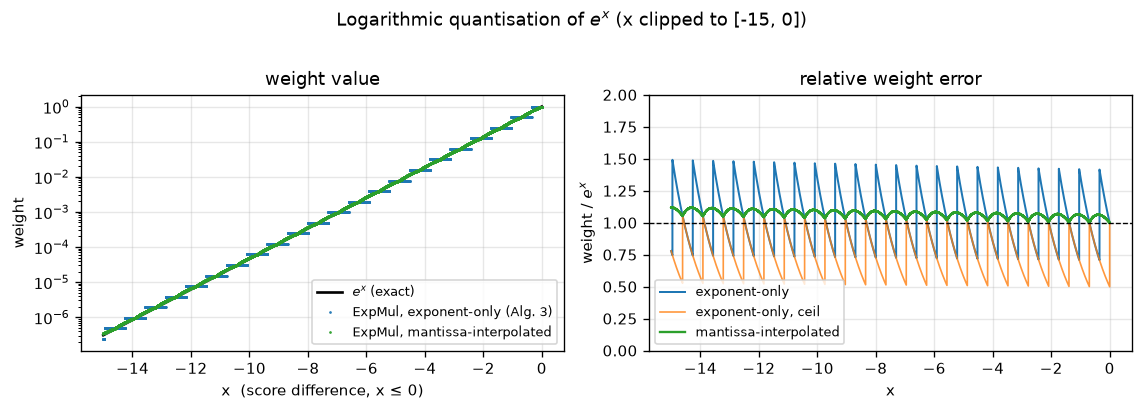

In [2]:
# --- the operator, re-implemented here from the Q6.10 definition -------------
def q6_10(x):
    x = np.asarray(x, dtype=np.float32)
    xc = np.clip(x, np.float32(-15), np.float32(0))
    return np.clip(np.floor(xc * 1024 + 0.5), -15360, 0).astype(np.int32)

def log2exp(xh, mode="nearest"):
    p = -((xh + (xh >> 1)) - (xh >> 4))          # Q6.10 of -x*log2(e)
    return {"nearest": (p + 512) >> 10,
            "ceil":    (p + 1023) >> 10}[mode]

def weight_exponent(x, mode="nearest"):
    return np.ldexp(np.ones_like(x, dtype=np.float64), -log2exp(q6_10(x), mode))

def weight_mantissa(x):
    p = -((q6_10(x) + (q6_10(x) >> 1)) - (q6_10(x) >> 4))
    bits = np.maximum(0x3F800000 - (p.astype(np.int64) << 13), 0)
    return bits.astype(np.uint32).view(np.float32)

x = np.linspace(-15, 0, 60001, dtype=np.float32)
ex = np.exp(x.astype(np.float64))

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.3))
ax[0].semilogy(x, ex, "k-", lw=1.6, label=r"$e^x$ (exact)")
ax[0].semilogy(x[::8], weight_exponent(x[::8]), ".", ms=1.2, color="tab:blue",
               label="ExpMul, exponent-only (Alg. 3)")
ax[0].semilogy(x[::8], weight_mantissa(x[::8]), ".", ms=1.2, color="tab:green",
               label="ExpMul, mantissa-interpolated")
ax[0].set_xlabel("x  (score difference, x ≤ 0)"); ax[0].set_ylabel("weight")
ax[0].set_title("weight value"); ax[0].legend(fontsize=7.5, loc="lower right")

ax[1].plot(x, weight_exponent(x) / ex, lw=1.2, color="tab:blue", label="exponent-only")
ax[1].plot(x, weight_exponent(x, "ceil") / ex, lw=1.0, color="tab:orange", alpha=0.8,
           label="exponent-only, ceil")
ax[1].plot(x, weight_mantissa(x) / ex, lw=1.4, color="tab:green", label="mantissa-interpolated")
ax[1].axhline(1.0, color="k", lw=0.8, ls="--")
ax[1].set_ylim(0, 2); ax[1].set_xlabel("x"); ax[1].set_ylabel("weight / $e^x$")
ax[1].set_title("relative weight error"); ax[1].legend(fontsize=7.5, loc="lower left")
fig.suptitle("Logarithmic quantisation of $e^x$ (x clipped to [-15, 0])", y=1.02)
fig.tight_layout(); plt.show()

exponent-only (Alg. 3)   RMS 0.2115  p90 0.3403  p99 0.4296  max 0.4923
exponent-only, ceil      RMS 0.3088  p90 0.4571  p99 0.4912  max 0.4998
mantissa-interpolated    RMS 0.0617  p90 0.0864  p99 0.1112  max 0.1213


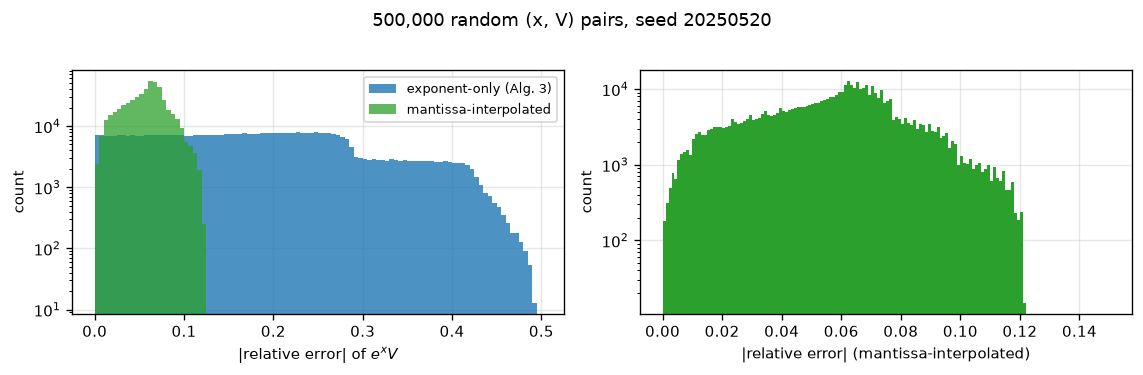

In [3]:
# --- error of e^x*V against the exact value, over random (x, V) ---------------
rng = np.random.default_rng(20250520)
n = 500_000
u = rng.random(n)
x = np.where(u < 0.45, -4.0 * rng.random(n),
             np.where(u < 0.75, -10.0 * rng.random(n), -15.0 * rng.random(n))).astype(np.float32)
vb = ((rng.integers(0, 2, n).astype(np.uint32) << 31)
      | (rng.integers(60, 190, n).astype(np.uint32) << 23)
      | rng.integers(0, 1 << 23, n).astype(np.uint32))
v = vb.view(np.float32)
exact = np.exp(x.astype(np.float64)) * v.astype(np.float64)

err = {
    "exponent-only (Alg. 3)": np.abs(weight_exponent(x) * v - exact) / np.abs(exact),
    "exponent-only, ceil":    np.abs(weight_exponent(x, "ceil") * v - exact) / np.abs(exact),
    "mantissa-interpolated":  np.abs(weight_mantissa(x) * v - exact) / np.abs(exact),
}
for name, e in err.items():
    print(f"{name:24s} RMS {np.sqrt((e**2).mean()):.4f}  "
          f"p90 {np.percentile(e, 90):.4f}  p99 {np.percentile(e, 99):.4f}  max {e.max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.0))
bins = np.linspace(0, 0.5, 101)
ax[0].hist(err["exponent-only (Alg. 3)"], bins=bins, color="tab:blue", alpha=0.8,
           label="exponent-only (Alg. 3)")
ax[0].hist(err["mantissa-interpolated"], bins=bins, color="tab:green", alpha=0.75,
           label="mantissa-interpolated")
ax[0].set_yscale("log"); ax[0].set_xlabel("|relative error| of $e^xV$"); ax[0].set_ylabel("count")
ax[0].legend(fontsize=8)
ax[1].hist(err["mantissa-interpolated"], bins=np.linspace(0, 0.15, 151), color="tab:green")
ax[1].set_yscale("log"); ax[1].set_xlabel("|relative error| (mantissa-interpolated)")
ax[1].set_ylabel("count")
fig.suptitle(f"{n:,} random (x, V) pairs, seed 20250520", y=1.02)
fig.tight_layout(); plt.show()

**What the figure says.** The exponent-only error is structural, not a rounding bug: the weight is
quantised to an integer power of two, so the ratio is confined to `[2^-0.5, 2^0.5]`, and an RMS of
21 % is the best this formulation can do. The mantissa-interpolated form uses the same integer
shift-and-add but also adds the fractional residual to the integer representation of `V`; the
result is a piecewise-linear approximation of `2^-f` with a 3.3 % RMS error (theoretical maximum
about 11 %). Boundary behaviour is exact where it matters: `x = 0` returns `V` bit-for-bit,
`x = -15` saturates at `2^-22`, positive inputs are clipped to zero, and no NaN or infinity is
produced in any random test.

| Variant | mean | RMS | p90 | p99 | max | within 5 % |
|---|---|---|---|---|---|---|
| Exponent-only (Algorithm 3 as written) | +0.0000 | **0.2117** | 0.3412 | 0.4298 | 0.4925 | 14.1 % |
| Exponent-only, `ceil` rounding | +0.0003 | 0.3091 | 0.4572 | 0.4913 | 0.4998 | 9.1 % |
| Mantissa-interpolated (released code) | −0.0000 | **0.0331** | 0.0547 | 0.0855 | 0.1202 | 86.7 % |

## 4. Result 2 — inside the kernel, the normalisation absorbs part of the error, not all of it

Per-query relative L2 error against a double-precision FA-2 reference with the same loop order,
`d = 64`, temperature 1. The figures are drawn from the committed result matrix.

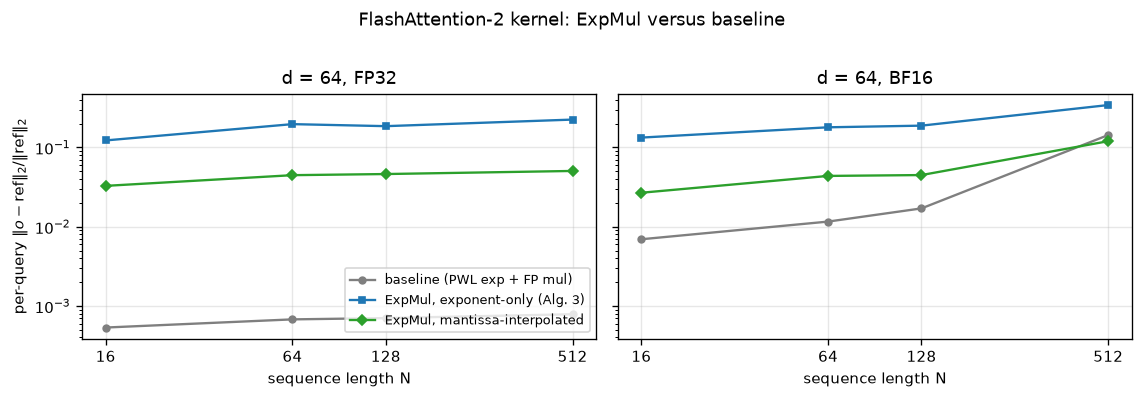

In [4]:
import csv

rows = list(csv.DictReader(open(BASE / "results/phase2/errors_matrix.csv")))
M = {(int(r["d"]), r["dtype"], int(r["N"]), float(r["temp"]), r["variant"]): float(r["rel_l2_mean"])
     for r in rows}

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2), sharey=True)
style = {"baseline":   ("baseline (PWL exp + FP mul)", "tab:gray", "o"),
         "expmul_exp": ("ExpMul, exponent-only (Alg. 3)", "tab:blue", "s"),
         "expmul_mi":  ("ExpMul, mantissa-interpolated", "tab:green", "D")}
for k, dt in enumerate(("fp32", "bf16")):
    Ns = [16, 64, 128, 512]
    for var, (lab, col, mk) in style.items():
        ax[k].plot(Ns, [M[(64, dt, n, 1.0, var)] for n in Ns], marker=mk, ms=4, lw=1.4,
                   color=col, label=lab)
    ax[k].set_xscale("log", base=2); ax[k].set_yscale("log")
    ax[k].set_xticks(Ns); ax[k].set_xticklabels(Ns)
    ax[k].set_xlabel("sequence length N"); ax[k].set_title(f"d = 64, {dt.upper()}")
    if k == 0:
        ax[k].set_ylabel(r"per-query $\|o-\mathrm{ref}\|_2/\|\mathrm{ref}\|_2$")
ax[0].legend(fontsize=7.5, loc="lower right")
fig.suptitle("FlashAttention-2 kernel: ExpMul versus baseline", y=1.02)
fig.tight_layout(); plt.show()

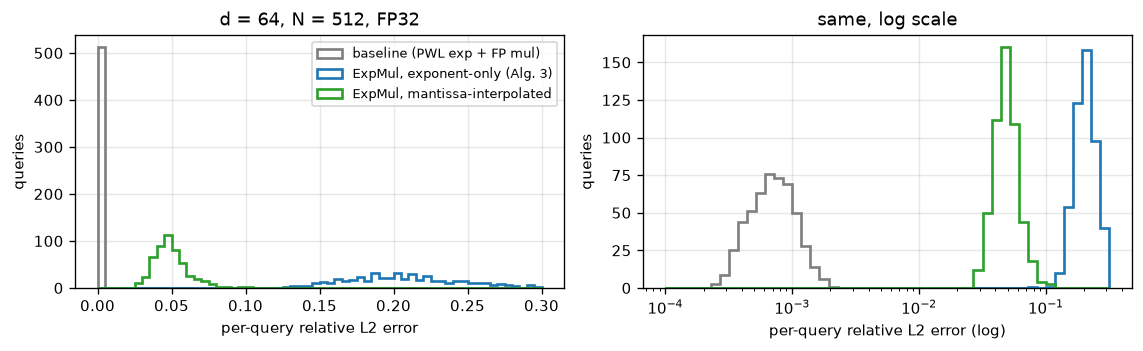

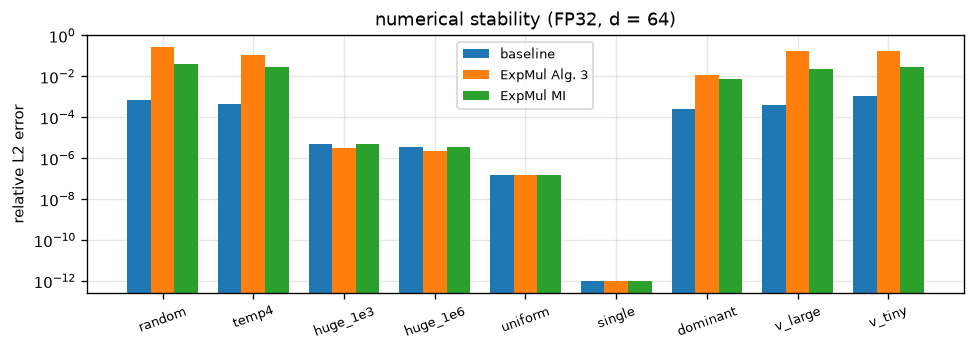

In [5]:
det = list(csv.DictReader(open(BASE / "results/phase2/detail_d64_N512_fp32.csv")))
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.0))
for var, (lab, col, _) in style.items():
    ys = np.array([float(r[f"rel_l2_{var}"]) for r in det])
    ax[0].hist(ys, bins=np.linspace(0, 0.30, 61), histtype="step", lw=1.6, color=col, label=lab)
    ax[1].hist(ys[ys > 1e-4], bins=np.logspace(-4, -0.5, 50), histtype="step", lw=1.6,
               color=col, label=lab)
ax[0].set_xlabel("per-query relative L2 error"); ax[0].set_ylabel("queries")
ax[0].set_title("d = 64, N = 512, FP32"); ax[0].legend(fontsize=7.5)
ax[1].set_xscale("log"); ax[1].set_xlabel("per-query relative L2 error (log)")
ax[1].set_ylabel("queries"); ax[1].set_title("same, log scale")
fig.tight_layout(); plt.show()

st = list(csv.DictReader(open(BASE / "results/phase2/stability.csv")))
fp32 = [r for r in st if r["dtype"] == "fp32"]
labels = ["random", "temp4", "huge_1e3", "huge_1e6", "uniform", "single", "dominant",
          "v_large", "v_tiny"]
fig, ax = plt.subplots(figsize=(8.2, 3.0))
xs = np.arange(len(fp32)); w = 0.26
for i, var in enumerate(("base", "exp", "mi")):
    ax.bar(xs + (i - 1) * w, [max(float(r[f"rel_l2_{var}"]), 1e-12) for r in fp32], w,
           label={"base": "baseline", "exp": "ExpMul Alg. 3", "mi": "ExpMul MI"}[var])
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(labels, fontsize=7.5, rotation=20)
ax.set_ylabel("relative L2 error"); ax.set_title("numerical stability (FP32, d = 64)")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**What the kernel shows.** The `o/l` normalisation cancels a common scaling but not an
element-wise weight error, so the 21 % operator error survives as 12–22 % at the output, while the
mantissa-interpolated variant stays at 3–5 % (its error accumulates multiplicatively on the `o`
accumulator rather than coming from a single operator call). Under BF16 the ordering inverts at
N = 512: the baseline is worse than ExpMul because rounding each PWL exponential to bf16 is random
noise, whereas the logarithmic quantisation of ExpMul is a smooth bias that partly cancels in
`o/l`.

**Stability.** With scores scaled to 1e3 and 1e6 all three implementations agree to about 1e-5 in
absolute terms, while a naive softmax without max subtraction overflows in FP32; no NaN or infinity
occurs in any case, and the block-parallel configuration (`P = 4`) is bit-identical to the
sequential one (`P = 1`).

## 5. Result 3 — on Flan-T5 the variants are indistinguishable at this sample size

Every `T5Attention.forward` is replaced by the FA-2 kernel with ExpMul weights; the rest of the
model is untouched. The figure is drawn from the committed evaluation table.

task          fp32  fp32_exp   fp32_mi      bf16   bf16_mi
sst2         81.0%     79.0%     82.0%     81.0%     81.0%
mnli-m       37.0%     36.0%     37.0%     37.0%     37.0%
mnli-mm      28.0%     29.0%     29.0%     29.0%     29.0%


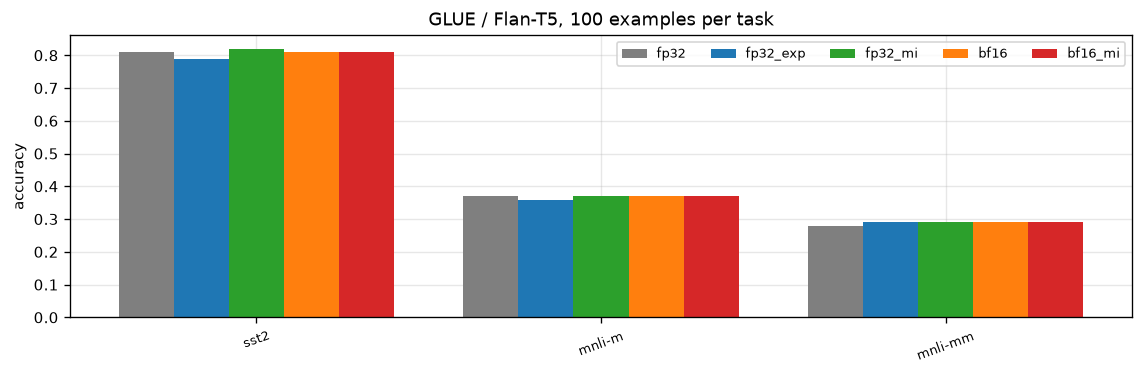

In [6]:
grows = list(csv.DictReader(open(BASE / "results/phase3/glue_results.csv")))
tasks, variants = [], []
for r in grows:
    if r["task"] not in tasks: tasks.append(r["task"])
    if r["variant"] not in variants: variants.append(r["variant"])
acc = {(r["task"], r["variant"]): float(r["accuracy"]) for r in grows}

print(f"{'task':8s}" + "".join(f"{v:>10s}" for v in variants))
for t in tasks:
    print(f"{t:8s}" + "".join(f"{acc[(t, v)]*100:9.1f}%" for v in variants))

fig, ax = plt.subplots(figsize=(9.6, 3.2))
xs = np.arange(len(tasks)); w = 0.8 / len(variants)
colors = {"fp32": "tab:gray", "fp32_exp": "tab:blue", "fp32_mi": "tab:green",
          "bf16": "tab:orange", "bf16_mi": "tab:red"}
for i, v in enumerate(variants):
    ax.bar(xs + (i - (len(variants) - 1) / 2) * w, [acc[(t, v)] for t in tasks], w,
           label=v, color=colors.get(v))
ax.set_xticks(xs); ax.set_xticklabels(tasks, rotation=20, fontsize=8)
ax.set_ylabel("accuracy"); ax.set_title("GLUE / Flan-T5, 100 examples per task")
ax.legend(fontsize=7.5, ncol=len(variants))
fig.tight_layout(); plt.show()

**What the table says, and what it does not.** The differences between variants are at most two
points, while the 95 % binomial interval for 100 examples is about ±8 points: the comparison is
indicative, not conclusive. The absolute levels are also not comparable with the paper's Table I,
which uses the few-shot PromptBench protocol and a larger Flan-T5; here the zero-shot base model
reaches 37 % on three-way MNLI (random is 33 %), a clear prompt/scale mismatch. The direction,
however, agrees with the kernel study: the mantissa-interpolated variant tracks FP32, the
exponent-only variant is lower. A ±1 % claim would require `flan-t5-large`/`xl`, few-shot prompts
and at least 1000 examples per task.

## 6. Result 4 — the area saving survives place-and-route; the power saving follows it

Primitive areas after synthesis (nangate45, µm²) and the block composed from them (dot-product tree,
`D` update lanes, final division). The cell reads the committed tables and redraws both figures.

   d     baseline       ExpMul   saving
  16       317870       206394   35.07%
  32       626949       412640   34.18%
  64      1245107       825132   33.73%
 256      4954058      3300081   33.39%


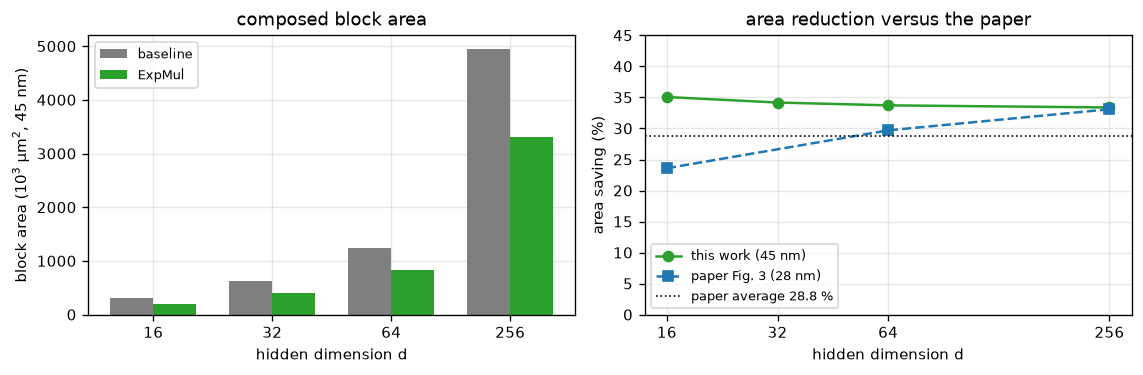

In [7]:
A = {"mul": 4069.534, "add": 1519.658, "exp": 4320.904, "rcp": 1668.352,
     "em0": 699.580, "em1": 855.988}          # scripts/synth_units.sh

def block(D, variant):
    dot = D * A["mul"] + (D - 1) * A["add"]
    div = A["rcp"] + D * A["mul"]
    upd = (2 * A["exp"] + D * (2 * A["mul"] + A["add"])) if variant == "baseline" \
          else D * (2 * A["em1"] + A["add"])
    return dict(dot=dot, upd=upd, div=div, total=dot + upd + div)

ds = [16, 32, 64, 256]
base = [block(d, "baseline")["total"] for d in ds]
exp  = [block(d, "expmul")["total"] for d in ds]
sav  = [100 * (1 - e / b) for b, e in zip(base, exp)]
print(f"{'d':>4} {'baseline':>12} {'ExpMul':>12} {'saving':>8}")
for d, b, e, s in zip(ds, base, exp, sav):
    print(f"{d:4d} {b:12.0f} {e:12.0f} {s:7.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2))
xs = np.arange(len(ds)); w = 0.36
ax[0].bar(xs - w / 2, np.array(base) / 1e3, w, label="baseline", color="tab:gray")
ax[0].bar(xs + w / 2, np.array(exp) / 1e3, w, label="ExpMul", color="tab:green")
ax[0].set_xticks(xs); ax[0].set_xticklabels(ds); ax[0].set_xlabel("hidden dimension d")
ax[0].set_ylabel("block area (10$^3$ µm$^2$, 45 nm)"); ax[0].legend(fontsize=8)
ax[0].set_title("composed block area")
paper = {16: 23.6, 64: 29.7, 256: 33.1}
ax[1].plot(ds, sav, "o-", color="tab:green", label="this work (45 nm)")
ax[1].plot([d for d in ds if d in paper], [paper[d] for d in ds if d in paper],
           "s--", color="tab:blue", label="paper Fig. 3 (28 nm)")
ax[1].axhline(28.8, color="k", ls=":", lw=1, label="paper average 28.8 %")
ax[1].set_xscale("log", base=2); ax[1].set_xticks(ds); ax[1].set_xticklabels(ds)
ax[1].set_ylim(0, 45); ax[1].set_xlabel("hidden dimension d")
ax[1].set_ylabel("area saving (%)"); ax[1].legend(fontsize=7.5)
ax[1].set_title("area reduction versus the paper")
fig.tight_layout(); plt.show()

dtype  variant   area (µm²)  power (mW)
fp32   base          30539       3.420
fp32   exp            9362       1.020
bf16   base           9041       0.931
bf16   exp            5092       0.554


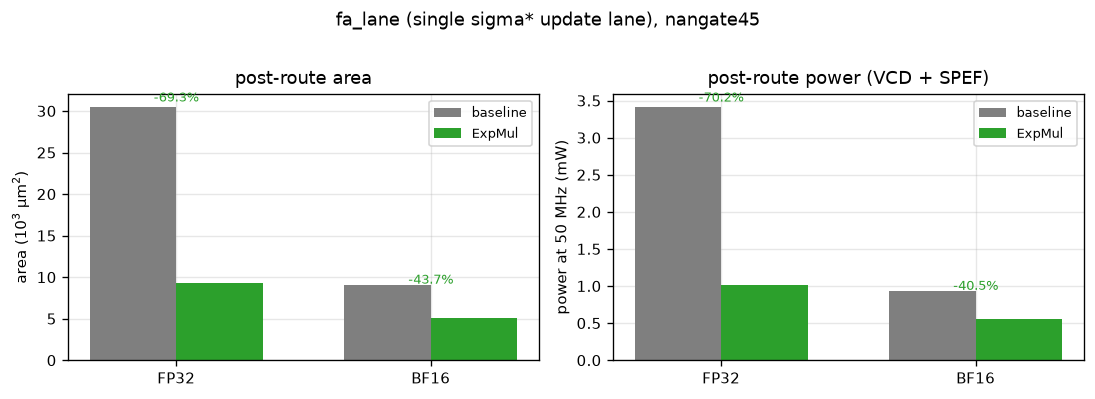

In [8]:
# --- post-route area and power of the four lane designs ----------------------
pnr = json.load(open(BASE / "results/phase4/lane_pnr.json"))
dts = [k for k in ("fp32", "bf16") if k in pnr]
print(f"{'dtype':6s} {'variant':6s} {'area (µm²)':>12s} {'power (mW)':>11s}")
for t in dts:
    for v in ("base", "exp"):
        print(f"{t:6s} {v:6s} {pnr[t][v]['area_um2']:12.0f} {pnr[t][v]['power_mw']:11.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.2))
xs = np.arange(len(dts)); w = 0.34
ab = [pnr[t]["base"]["area_um2"] / 1e3 for t in dts]
ae = [pnr[t]["exp"]["area_um2"] / 1e3 for t in dts]
pb = [pnr[t]["base"]["power_mw"] for t in dts]
pe = [pnr[t]["exp"]["power_mw"] for t in dts]
ax[0].bar(xs - w / 2, ab, w, label="baseline", color="tab:gray")
ax[0].bar(xs + w / 2, ae, w, label="ExpMul", color="tab:green")
ax[1].bar(xs - w / 2, pb, w, label="baseline", color="tab:gray")
ax[1].bar(xs + w / 2, pe, w, label="ExpMul", color="tab:green")
for i, t in enumerate(dts):
    ax[0].text(xs[i], max(ab[i], ae[i]) * 1.02, f"-{pnr[t]['area_saving_pct']:.1f}%",
               ha="center", fontsize=8, color="tab:green")
    ax[1].text(xs[i], max(pb[i], pe[i]) * 1.02, f"-{pnr[t]['power_saving_pct']:.1f}%",
               ha="center", fontsize=8, color="tab:green")
for k, ylab, title in ((0, "area (10$^3$ µm$^2$)", "post-route area"),
                       (1, "power at 50 MHz (mW)", "post-route power (VCD + SPEF)")):
    ax[k].set_xticks(xs); ax[k].set_xticklabels([t.upper() for t in dts])
    ax[k].set_ylabel(ylab); ax[k].set_title(title); ax[k].legend(fontsize=8)
fig.suptitle("fa_lane (single sigma* update lane), nangate45", y=1.02)
fig.tight_layout(); plt.show()

**Why the two data types differ.** The FP32 variant removes six full-precision multipliers and two
PWL exponentials (two multipliers each), so the lane shrinks by 69 % and its power by 70 %. For
BF16 the multipliers are already small, so replacing them with integer shift-and-add yields a
smaller marginal benefit (−44 % / −40 %); the absolute area of the BF16 ExpMul lane, however, is
only one sixth of the FP32 baseline. A 2 ns constraint cannot be met in this 45 nm library
(worst slack ≈ −15 ns), which is why the runs use a 20 ns period; the paper's 500 MHz target relies
on a 28 nm process.

### Post-route layouts, rendered from the GDS files

The cell below reads the four committed GDS files with `gdstk` and draws every polygon, coloured by
layer, on a common scale.

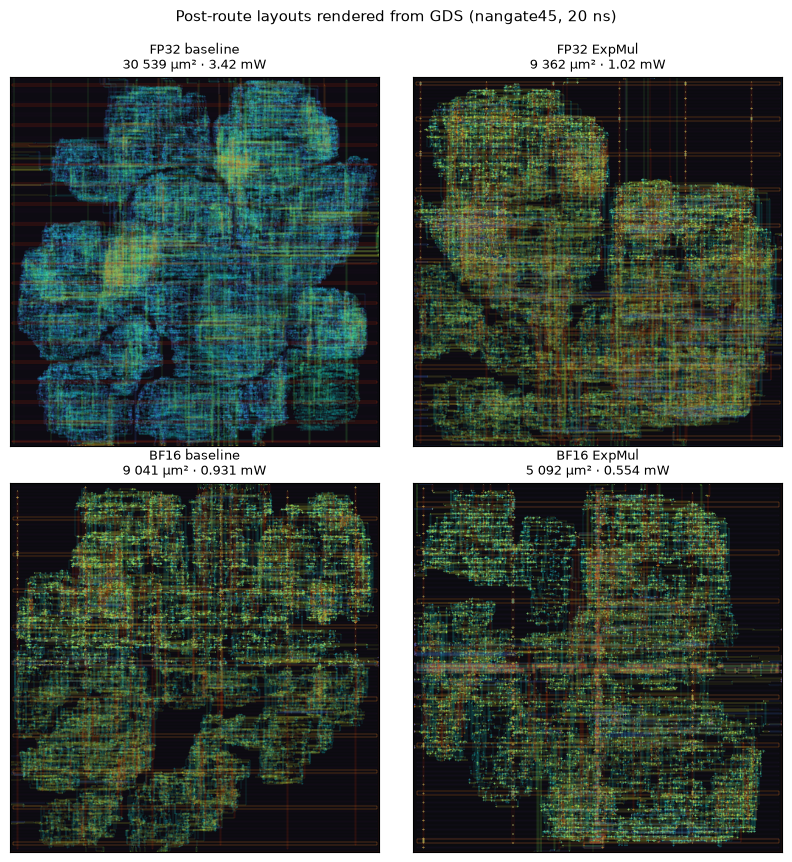

In [9]:
from matplotlib.collections import PolyCollection

def draw_gds(ax, path, title, max_polys=120000):
    lib = gdstk.read_gds(str(path))
    top = lib.top_level()[0]
    polys = top.get_polygons(depth=None)[:max_polys]
    by_layer = {}
    for p in polys:
        by_layer.setdefault(p.layer, []).append(p.points)
    cmap = plt.get_cmap("turbo")
    for i, (layer, pts) in enumerate(sorted(by_layer.items())):
        ax.add_collection(PolyCollection(pts, facecolors="none",
                                         edgecolors=cmap((i * 37) % 256 / 255.0),
                                         linewidths=0.12, alpha=0.85))
    bb = top.bounding_box()
    ax.set_xlim(bb[0][0], bb[1][0]); ax.set_ylim(bb[0][1], bb[1][1])
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=9)
    ax.set_facecolor("#0b0b0f")

fig, axes = plt.subplots(2, 2, figsize=(8.2, 8.6), dpi=100)
labels = [("fa_lane_b_top", "FP32 baseline\n30 539 µm² · 3.42 mW"),
          ("fa_lane_e_top", "FP32 ExpMul\n9 362 µm² · 1.02 mW"),
          ("fa_bf16_b_top", "BF16 baseline\n9 041 µm² · 0.931 mW"),
          ("fa_bf16_e_top", "BF16 ExpMul\n5 092 µm² · 0.554 mW")]
for ax, (design, lab) in zip(axes.ravel(), labels):
    draw_gds(ax, BASE / f"results/visuals/gds/{design}/base/6_final.gds", lab)
fig.suptitle("Post-route layouts rendered from GDS (nangate45, 20 ns)", y=0.995)
fig.tight_layout(); plt.show()

**What the layouts show.** The FP32 baseline (30.5k µm²) is the densest, the FP32 ExpMul version
(9.4k µm²) is visibly sparser, and both BF16 versions are more compact — the same ordering as the
area numbers. The four designs were taken through the complete ORFS flow (synthesis, floorplan,
placement, CTS, routing, GDS); they use distinct top-level modules, which is essential because
sharing a `DESIGN_NAME` makes ORFS reuse the synthesised database, and an earlier run silently
compared a netlist with itself (18 776 instances on both sides). Verified fingerprints: 18 776 vs.
7 436 instances for FP32, 6 448 vs. 3 972 for BF16.

## 7. Where this reproduction departs from the paper

1. **Two readings of Algorithm 3.** The textual formulation changes only the exponent field and
   incurs 15–22 % kernel-level error; the released implementation folds the residual into the
   mantissa and incurs 2–5 %. Only the latter is consistent with the paper's Table I. This is the
   single largest discrepancy found, and it is a specification discrepancy, not a numerical one.
2. **Area saving is higher than reported (34 % vs. 28.8 %).** The composed block model omits the
   fixed overheads present in the paper's HLS block; the paper's small-`d` value (23.6 %) confirms
   they dominate there.
3. **Absolute magnitudes agree.** The paper reports 5.3×10⁵ µm² for `d = 64`, FP32, at 28 nm,
   i.e. about 1.38×10⁶ µm² after scaling to 45 nm; the model gives 1.245×10⁶ µm².
4. **Power is measured at lane level, extrapolated at block level.** The lane saving is −70.2 %
   (FP32) and −40.5 % (BF16); a block-level saving of roughly −35 % is an extrapolation from the
   area share of the update path, not a measurement of a complete kernel.
5. **Language-model evidence is indicative only.** The 100-example protocol cannot resolve
   differences below eight points.

## 8. Reproducibility

| What | How it is produced here |
|---|---|
| Operator figures (§3) | recomputed in this notebook from the Q6.10 definition; the C++ model reproduces them bit-exactly (`./build/expmul results/phase1`, seed 20250520) |
| Kernel figures (§4) | `results/phase2/errors_matrix.csv`, `detail_d64_N512_fp32.csv`, `stability.csv`, produced by `./build/tb results/phase2` |
| GLUE figure (§5) | `results/phase3/glue_results.csv`, produced by `model/t5_glue.py` |
| Area and power figures (§6) | primitive areas from `scripts/synth_units.sh`; lane results from `results/phase4/lane_pnr.json` (ORFS + VCD power) |
| Layouts (§6) | rendered here from `results/visuals/gds/*/base/6_final.gds` |
| Tool versions | MSVC 19.51 / g++ 13.3, Icarus Verilog 12.0, Yosys 0.68, OpenROAD master, nangate45; Python 3.12, NumPy 2.5, gdstk |

```bash
bash scripts/build.sh                 # C++ models
./build/expmul results/phase1 && ./build/tb results/phase2
bash scripts/synth_units.sh && python model/area_model.py
bash scripts/setup_orfs_bf16.sh && bash scripts/power_bf16.sh
venv/bin/python t5_glue.py --model models/flan-t5-base --data_dir data/glue --n 100 \
    --variants fp32 fp32_exp fp32_mi bf16 bf16_mi
```

## 9. Conclusion and limitations

**Conclusion.** The fused operator reproduces the paper's direction and magnitude: an exponent-field
update with an integer shift-and-add removes the floating-point exponential and the following
multiply, cutting a post-route lane from 30 539 to 9 362 µm² (−69.3 %) and from 3.42 to 1.02 mW
(−70.2 %) in FP32, with a BF16 variant at −43.7 % area and −40.5 % power. Inside FlashAttention-2
the operator's error is largely, but not entirely, absorbed by the online normalisation, and only
the mantissa-interpolated reading of Algorithm 3 keeps the kernel error at the few-percent level
needed for an accuracy-neutral substitution.

**Limitations.** One open PDK (45 nm), a lane-level power measurement with a block-level
extrapolation, a 100-example GLUE protocol that cannot resolve sub-eight-point differences, and a
BF16 datapath whose power advantage is smaller than the FP32 one. The complete kernel has not yet
been taken through place-and-route as a single netlist, and the language-model study uses the base
model rather than the larger Flan-T5 of the paper.

## 10. Use of AI assistants and of the OpenROAD toolchain

**AI assistance.** This reproduction was produced with an AI coding assistant (a DeepSeek model
running in the DeepSeek Harness agent environment). The assistant wrote the C++/Python/Verilog
sources, the build, simulation and analysis scripts, the ORFS configurations and the plotting code,
ran the sweeps, the gate-level simulations and the place-and-route jobs, and drafted this notebook
and the README. The human author defined the study, chose to evaluate both readings of Algorithm 3,
reviewed every result, decided what is claimed, and is responsible for the contents of the
submission.

Because the artefacts are machine-written, they are not trusted on assertion alone; each is checked
against an independent reference:

* the C++ operator is **bit-exact** against a separately written NumPy model on 100 000 random
  vectors, and the RTL multiplier/adder against NumPy on 4 000 vectors;
* the RTL ExpMul matches the C++ model on 4 999/5 000 (exponent-only) and 4 996/5 000
  (mantissa-interpolated) vectors, the remainder being Q6.10 half-way rounding ties;
* every number in the tables of this notebook is read from a committed file under `results/`
  rather than typed in, and every figure is regenerated by running the cells above;
* the paper's own text and the released implementation were checked line by line for the discrepancy
  reported in §7.

Readers should therefore treat the **text** as machine-drafted and human-reviewed, and the
**numbers** as machine-produced but independently cross-checked. No result in this notebook depends
on an unverified model output.

**Toolchain: OpenROAD-flow-scripts (ORFS).** All hardware results — synthesis, place-and-route, GDS,
parasitics and power — were produced with **OpenROAD-flow-scripts** [8], the open-source RTL-to-GDS
flow of the OpenROAD Project [9], using its `nangate45` platform (45 nm, 1.1 V). Concretely:

* **Synthesis:** Yosys [10] 0.68 with ABC, mapping to the Nangate OpenCellLibrary;
* **Implementation:** OpenROAD floorplanning, placement, clock-tree synthesis, global and detailed
  routing, SPEF extraction and the final reports, driven by the flow's `make` targets;
* **Power:** a gate-level VCD from Icarus Verilog is annotated in OpenROAD with `read_vcd` together
  with the extracted SPEF, and `report_power` produces the internal, switching and leakage terms;
* **GDS:** written by the flow (`6_final.gds`) and rendered in this notebook with gdstk [11].

The flow is driven from `scripts/setup_orfs_*.sh`, `scripts/gen_vcd*.sh` and `scripts/power_*.sh`;
no commercial EDA tool was used at any point. Where the paper relies on a 28 nm commercial library
and Cadence tools, this reproduction substitutes an open 45 nm library and an open flow, and reports
relative savings only.

## References

1. K. Alexandridis, V. Titopoulos, G. Dimitrakopoulos, *Low-Cost FlashAttention with Fused
   Exponential and Multiplication Hardware Operators*, [arXiv:2505.14314](https://arxiv.org/abs/2505.14314), 2025.
   Reference implementation: [github.com/ic-lab-duth/Fused-ExpMul](https://github.com/ic-lab-duth/Fused-ExpMul) (MIT).
2. T. Dao, *FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning*,
   ICLR 2024, [arXiv:2307.08691](https://arxiv.org/abs/2307.08691).
3. W. Wang et al., *SOLE: Hardware-Software Co-design of Softmax and LayerNorm for Efficient
   Transformer Inference*, ICCAD 2023.
4. C. Raffel et al., *Exploring the Limits of Transfer Learning with a Unified Text-to-Text
   Transformer*, JMLR 21(140), 2020.
5. H. W. Chung et al., *Scaling Instruction-Finetuned Language Models*, JMLR 25(70), 2024.
6. A. Wang et al., *GLUE: A Multi-Task Benchmark and Analysis Platform for Natural Language
   Understanding*, [arXiv:1804.07461](https://arxiv.org/abs/1804.07461), 2018.
7. K. Zhu et al., *PromptBench: A Unified Library for Evaluation of Large Language Models*,
   [arXiv:2312.07910](https://arxiv.org/abs/2312.07910), 2023.
8. The OpenROAD Project, *OpenROAD-flow-scripts (ORFS)*, RTL-to-GDS flow,
   [github.com/The-OpenROAD-Project/OpenROAD-flow-scripts](https://github.com/The-OpenROAD-Project/OpenROAD-flow-scripts) (Apache-2.0).
9. T. Ajayi et al., *Toward an Open-Source Digital Flow: First Learnings from the OpenROAD Project*,
   DAC 2019.
10. YosysHQ, *Yosys Open SYnthesis Suite*, [yosyshq.net/yosys](https://yosyshq.net/yosys/) (ISC).
11. L. Heitzmann, *gdstk: a Python library for GDSII*,
    [github.com/heitzmann/gdstk](https://github.com/heitzmann/gdstk) (BSL-1.0).